# RDF. Модель данных и способы сериализации.

__Автор задач: Блохин Н.В. (NVBlokhin@fa.ru)__

Материалы:
* Курс лекций, лекция №01
* [RDF 1.2 Concepts and Abstract Syntax](https://www.w3.org/TR/rdf12-concepts/)
* [RDF 1.2 N-Triples](https://www.w3.org/TR/rdf12-n-triples/)
* [RDF 1.2 Turtle](https://www.w3.org/TR/rdf12-turtle/)
* [JSON-LD 1.1](https://www.w3.org/TR/json-ld11/)
* [ShExValidata (W3C)](https://www.w3.org/2015/03/ShExValidata/)
* [JSON-LD Playground](https://json-ld.org/playground/)
* [Конвертер RDF isSemantic](https://issemantic.net/rdf-converter)
* https://networkx.org/documentation/stable/reference/classes/digraph.html
* https://networkx.org/documentation/stable/reference/drawing.html
* https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html
* https://docs.python.org/3/library/uuid.html

## Задачи для совместного разбора

1\. Обсудите модель RDF: тройка, идентификаторы, литералы, языковые теги и типы данных, пустые узлы.

RDF описывает данные утверждениями из трех частей: субъект, предикат, объект. Одно утверждение - это один факт.

Набор таких утверждений образует ориентированный граф, субъект и объект - узлы, предикат - направленное ребро. Такие графы будем называть графами знаний.

В RDF субъект и предикат обязаны быть **URI**, а не произвольной строкой. Например:
```
    <http://www.fa.ru/entity/MoscowStateUniversity>
    <http://www.fa.ru/predicate/city>
```

URI должен быть глобально уникален, и совпадение URI в двух разных источниках означает, что речь идет об одной и той же вещи. 


Объект, в отличие от субъекта и предиката, может быть не только URI, но и литералом - конкретным значением (строкой, числом, датой). 

У литерала бывает уточнение:

* языковой тег для текста на естественном языке: `"Москва"@ru`, `"Moscow"@en`;
* URI типа данных: `"1755-01-25"^^xsd:date`, `"40000"^^xsd:integer`.

Литерал без уточнения считается строкой (`xsd:string`).

Иногда нужен узел, у которого нет и не должно быть собственного имени: он существует только чтобы связать несколько значений. Пример - значение вроде адреса, где улица и дом принадлежат одной сущности, но давать этой сущности URI незачем.

Такой узел называется пустым (blank node) и записывается с префиксом `_:`

```turtle
e:MoscowStateUniversity p:address _:b1 .
_:b1 p:street "Ленинские горы" ;
     p:house  "1" .
```

На такой узел нельзя сослаться извне.

2\. Обсудите три сериализации одного графа: N-Triples, Turtle и JSON-LD.

Граф - это множество троек. Сериализация - это способ записать это множество в файл. Нам нужно обсудитьнесколько форматов:

N-Triples - максимально простой формат: одна тройка на строку, все URI записаны полностью в угловых скобках, строка заканчивается точкой.

```
<http://www.fa.ru/entity/MoscowStateUniversity> <http://www.fa.ru/predicate/name> "Московский государственный университет"@ru .
<http://www.fa.ru/entity/MoscowStateUniversity> <http://www.fa.ru/predicate/name> "Moscow State University"@en .
<http://www.fa.ru/entity/MoscowStateUniversity> <http://www.fa.ru/predicate/established> "1755-01-25"^^<http://www.w3.org/2001/XMLSchema#date> .
<http://www.fa.ru/entity/MoscowStateUniversity> <http://www.fa.ru/predicate/city> <http://www.fa.ru/entity/Moscow> .
<http://www.fa.ru/entity/Moscow> <http://www.fa.ru/predicate/name> "Москва"@ru .
```

Читать человеку неудобно, зато удобно обрабатывать машине.

Turtle - то же самое, но с сокращениями. Turtle имеет три доп. возможности:

* `@prefix` - объявление пространства имен, дальше пишется короткая форма;
* `;` - список предикатов: повторить тот же субъект для следующей пары предикат-объект;
* `,` - список объектов: повторить тот же субъект и предикат для следующего объекта.

```turtle
@prefix e:   <http://www.fa.ru/entity/> .
@prefix p:   <http://www.fa.ru/predicate/> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .

e:MoscowStateUniversity
    p:name        "Московский государственный университет"@ru, "Moscow State University"@en ;
    p:established "1755-01-25"^^xsd:date ;
    p:city        e:Moscow .

e:Moscow
    p:name "Москва"@ru .
```

JSON-LD - вариант записи графа в виде обычного JSON. Ключ `@context` задает соответствие между короткими именами и URI, `@id` - идентификатор сущности, `@type` - ее тип, `@language` и `@value` - языковой тег и значение литерала.

```json
{
  "@context": {
    "e": "http://www.fa.ru/entity/",
    "p": "http://www.fa.ru/predicate/",
    "xsd": "http://www.w3.org/2001/XMLSchema#",
    "name": {"@id": "p:name"},
    "established": {"@id": "p:established", "@type": "xsd:date"},
    "city": {"@id": "p:city", "@type": "@id"}
  },
  "@id": "e:MoscowStateUniversity",
  "name": [
    {"@value": "Московский государственный университет", "@language": "ru"},
    {"@value": "Moscow State University", "@language": "en"}
  ],
  "established": "1755-01-25",
  "city": {"@id": "e:Moscow", "name": {"@value": "Москва", "@language": "ru"}}
}

```

Смысл JSON-LD в том, что этот документ остается валидным JSON. При этом при наличии `@context` он однозначно разворачивается в тройки. 

3\. Обсудите проблему материализации утверждений (reification) и три схемы ее решения.

Тройка описывает факт, но не описывает обстоятельства факта. Пример: утверждение "МГУ - численность студентов - 40000". Без указания года утверждение бессмысленно. Нужно прикрепить к утверждению уточнение - квалификатор.

Но в тройке RDF его некуда засунуть. У  ребра нет места, куда положить дополнительное свойство. Приходится вводить искусственный узел, представляющий само утверждение. Эта процедура называется материализацией утверждения (reification), и способов ее выполнить существует несколько. Ниже приведены две, существуют и другие.

Схема 1

Заводится узел-утверждение, у которого три обязательных свойства - субъект, предикат и объект исходной тройки. Квалификаторы вешаются на этот же узел.

![Схема 1](data/reification.drawio.v1.png)

```turtle
@prefix hasSubject:   <http://www.fa.ru/hasSubject/> .
@prefix hasPredicate: <http://www.fa.ru/hasPredicate/> .
@prefix hasObject:    <http://www.fa.ru/hasObject/> .
@prefix entity:       <http://www.fa.ru/entity/> .
@prefix predicate:    <http://www.fa.ru/predicate/> .
@prefix statement:    <http://www.fa.ru/statement/> .

statement:s1
    hasSubject:   entity:MoscowStateUniversity ;
    hasPredicate: predicate:studentSize ;
    hasObject:    "40000" ;
    predicate:atYear "2000" .
```

Схема 2

Подход, который использует Wikidata. Субъект связывается с узлом-утверждением специальным свойством из пространства `p:`, внутри узла значение лежит под тем же именем в пространстве `ps:`, а квалификаторы - в пространстве `pq:`.

![Схема 2](data/reification.drawio.v2.png)

```turtle
@prefix e:  <http://www.fa.ru/entity/> .
@prefix p:  <http://www.fa.ru/prop/> .
@prefix ps: <http://www.fa.ru/prop/statement/> .
@prefix pq: <http://www.fa.ru/prop/qualifier/> .
@prefix s:  <http://www.fa.ru/entity/statement/> .

e:MoscowStateUniversity p:studentSize s:a1 .

s:a1 ps:studentSize "40000" ;
     pq:atYear      "2000" .
```
Это наша основная схема для дальнейшей работы.

## Задачи для самостоятельного решения

В файле `data/artist.txt` находится текст о художнице. Ниже приведены два разбора этого текста на тройки, выполненные по разным принципам.

In [64]:
from enum import Enum, auto


class Relation(Enum):
    NAME = auto()
    TITLE_EN = auto()
    IS_A = auto()
    AGE = auto()
    SPECIALIZATION = auto()
    LIVES_IN = auto()
    CREATED = auto()
    PART_OF_SERIES = auto()
    SERIES_SIZE = auto()
    CREATED_YEAR = auto()
    DEPICTS = auto()
    CANVAS_SIZE = auto()
    CANVAS_WIDTH_CM = auto()
    CANVAS_HEIGHT_CM = auto()
    SOLD_AT = auto()
    PRICE = auto()
    CURRENCY = auto()
    USES_TECHNIQUE = auto()
    DESCRIPTION = auto()
    FAVORITE_COLOR = auto()
    WORKSHOP = auto()
    ADDRESS = auto()
    STREET = auto()
    HOUSE = auto()
    PHONE = auto()
    TEACHES = auto()
    AUDIENCE = auto()
    HELD_AT = auto()


Triple = tuple[str, Relation, str]

In [65]:
PARSE_A: list[Triple] = [
    # Художница
    ("ID-1", Relation.IS_A, "художник"),
    ("ID-1", Relation.NAME, "Анна Петрова"),
    ("ID-1", Relation.AGE, "35 лет"),
    ("ID-1", Relation.SPECIALIZATION, "пейзажная живопись"),
    ("ID-1", Relation.LIVES_IN, "ID-2"),
    ("ID-1", Relation.FAVORITE_COLOR, "зеленый и синий"),
    ("ID-1", Relation.CREATED, "ID-3"),
    ("ID-1", Relation.WORKSHOP, "ID-6"),
    ("ID-1", Relation.TEACHES, "ID-7"),
    # Город
    ("ID-2", Relation.IS_A, "город"),
    ("ID-2", Relation.NAME, "Зеленогорск"),
    # Серия картин
    ("ID-3", Relation.IS_A, "серия картин"),
    ("ID-3", Relation.NAME, "Времена года"),
    ("ID-3", Relation.SERIES_SIZE, "четыре полотна"),
    # Картина
    ("ID-4", Relation.IS_A, "картина"),
    ("ID-4", Relation.NAME, "Весеннее пробуждение"),
    ("ID-4", Relation.PART_OF_SERIES, "ID-3"),
    ("ID-4", Relation.CREATED_YEAR, "в 2021 году"),
    ("ID-4", Relation.DEPICTS, "цветущий яблоневый сад на фоне голубого неба"),
    ("ID-4", Relation.CANVAS_SIZE, "80 на 60 сантиметров"),
    ("ID-4", Relation.SOLD_AT, "местный аукцион"),
    ("ID-4", Relation.PRICE, "150000 рублей"),
    ("ID-4", Relation.USES_TECHNIQUE, "ID-5"),
    # Техника
    ("ID-5", Relation.IS_A, "техника живописи"),
    ("ID-5", Relation.NAME, "импасто"),
    ("ID-5", Relation.DESCRIPTION, "объемные мазки масляными красками"),
    # Мастерская
    ("ID-6", Relation.IS_A, "мастерская"),
    ("ID-6", Relation.ADDRESS, "улица Лесная, дом 7"),
    ("ID-6", Relation.PHONE, "+7 (123) 456-78-90"),
    # Мастер-класс
    ("ID-7", Relation.IS_A, "мастер-класс"),
    ("ID-7", Relation.AUDIENCE, "начинающие художники"),
    ("ID-7", Relation.HELD_AT, "ID-6"),
    # Картина под зарубежным названием
    ("ID-8", Relation.IS_A, "картина"),
    ("ID-8", Relation.NAME, "Spring Awakening"),
]

In [66]:
PARSE_B: list[Triple] = [
    # Художница
    ("ID-1", Relation.IS_A, "художник"),
    ("ID-1", Relation.NAME, "Анна Петрова"),
    ("ID-1", Relation.AGE, "35"),
    ("ID-1", Relation.SPECIALIZATION, "пейзажная живопись"),
    ("ID-1", Relation.LIVES_IN, "Зеленогорск"),
    ("ID-1", Relation.FAVORITE_COLOR, "зеленый"),
    ("ID-1", Relation.FAVORITE_COLOR, "синий"),
    ("ID-1", Relation.CREATED, "ID-4"),
    ("ID-1", Relation.USES_TECHNIQUE, "импасто"),
    ("ID-1", Relation.STREET, "Лесная"),
    ("ID-1", Relation.HOUSE, "7"),
    ("ID-1", Relation.PHONE, "+7 (123) 456-78-90"),
    ("ID-1", Relation.TEACHES, "мастер-классы для начинающих художников"),
    # Картина
    ("ID-4", Relation.IS_A, "картина"),
    ("ID-4", Relation.NAME, "Весеннее пробуждение"),
    ("ID-4", Relation.TITLE_EN, "Spring Awakening"),
    ("ID-4", Relation.PART_OF_SERIES, "Времена года"),
    ("ID-4", Relation.CREATED_YEAR, "2021"),
    ("ID-4", Relation.DEPICTS, "цветущий яблоневый сад"),
    ("ID-4", Relation.DEPICTS, "голубое небо"),
    ("ID-4", Relation.CANVAS_WIDTH_CM, "80"),
    ("ID-4", Relation.CANVAS_HEIGHT_CM, "60"),
    ("ID-4", Relation.SOLD_AT, "местный аукцион"),
    ("ID-4", Relation.PRICE, "150000"),
    ("ID-4", Relation.CURRENCY, "RUB"),
]

<p class="task" id="1"></p>

1\. Даны шесть вопросов к данным:

1. Сколько полотен описано в тексте как отдельные картины?
2. Какова площадь холста «Весеннего пробуждения» в квадратных сантиметрах?
3. Какие сущности графа являются городами?
4. Какой техникой написано «Весеннее пробуждение»?
5. На какой улице находится мастерская?
6. Кому принадлежит указанный в тексте телефон?

Реализуйте функции `objects` и `subjects`. Используя только их, для каждого вопроса получите ответ по разбору A и по разбору B. Выведите результат в виде таблицы из трех столбцов: номер вопроса, ответ по A, ответ по B. Если разбор не позволяет ответить на вопрос, выведите в соответствующей ячейке `нет данных`.

Ответ должен извлекаться только из троек.

- [ ] Проверено на семинаре

In [67]:
import pandas as pd
from IPython.display import Markdown

In [68]:
def objects(triples: list[Triple], subject: str, relation: Relation) -> list[str]:
    """Вернуть объекты всех троек по заданным субъекту и отношению."""
    return [obj for sub, rel, obj in triples if sub==subject and rel == relation]
    

objects(PARSE_A, 'ID-1', Relation.IS_A)


['художник']

In [69]:
def subjects(triples: list[Triple], relation: Relation, obj: str) -> list[str]:
    """Вернуть субъекты всех троек по заданным отношению и объекту."""
    return [sub for sub, rel, obj_ in triples if obj==obj_ and rel == relation]    


subjects(PARSE_A, Relation.IS_A, 'художник')

['ID-1']

In [70]:
ans = [
    (objects(PARSE_A, 'ID-3', Relation.SERIES_SIZE)[0], len(subjects(PARSE_B,Relation.IS_A, 'картина'))),
    (objects(PARSE_A, 'ID-4', Relation.CANVAS_SIZE)[0], eval(objects(PARSE_B, 'ID-4', Relation.CANVAS_WIDTH_CM)[0]+'*'+objects(PARSE_B, 'ID-4', Relation.CANVAS_HEIGHT_CM)[0])),
    (subjects(PARSE_A, Relation.IS_A, 'город'), 'NO DATA'),
    (objects(PARSE_A, 'ID-5', Relation.NAME)[0], 'NO DATA'),
    (objects(PARSE_A, 'ID-6', Relation.ADDRESS)[0], objects(PARSE_B, 'ID-1', Relation.STREET)[0]),
    (objects(PARSE_A, "ID-6", Relation.IS_A)[0], objects(PARSE_B, "ID-1", Relation.NAME)[0])
]

display(Markdown(pd.DataFrame(ans, index=range(1,7), columns=['A', 'B']).to_markdown()
))

|    | A                    | B            |
|---:|:---------------------|:-------------|
|  1 | четыре полотна       | 1            |
|  2 | 80 на 60 сантиметров | 4800         |
|  3 | ['ID-2']             | NO DATA      |
|  4 | импасто              | NO DATA      |
|  5 | улица Лесная, дом 7  | Лесная       |
|  6 | мастерская           | Анна Петрова |

<p class="task" id="2"></p>

2\. Постройте ориентированный граф `nx.DiGraph` по каждому из двух разборов. На каждом ребре создайте атрибут `type`, в котором хранится значение типа отношения (`Relation`).

Визуализируйте оба графа. Добавьте на узлы и ребра подписи. В качестве подписи ребра используйте название перечисляемого значения. Сделайте нелитеральные субъекты и объекты зелеными, а литеральные объекты - серыми.

В текстовой ячейке опишите, чем два графа отличаются.

- [ ] Проверено на семинаре

In [71]:
import networkx as nx
import matplotlib.pyplot as plt


def graph_from_parse(triples: list[Triple]) -> nx.DiGraph:
    G = nx.DiGraph()

    for sub, rel, obj in triples:
        G.add_edge(sub, obj, type=rel)

    return G


A = graph_from_parse(PARSE_A)
B = graph_from_parse(PARSE_B)

In [72]:
def draw_parse_graph(graph):
    plt.figure(figsize=(12, 12))

    pos = nx.spring_layout(graph, seed=42)

    colors = []

    for node in graph.nodes:
        if node.startswith("ID-"):
            colors.append("green")
        else:
            colors.append("lightgray")

    nx.draw(
        graph,
        pos,
        with_labels=True,
        node_color=colors,
        node_size=1800,
        font_size=7,
        arrows=True
    )

    edge_labels = {}

    for start, end, data in graph.edges(data=True):
        edge_labels[(start, end)] = data["type"].name

    nx.draw_networkx_edge_labels(
        graph,
        pos,
        edge_labels=edge_labels,
        font_size=6
    )

    plt.show()

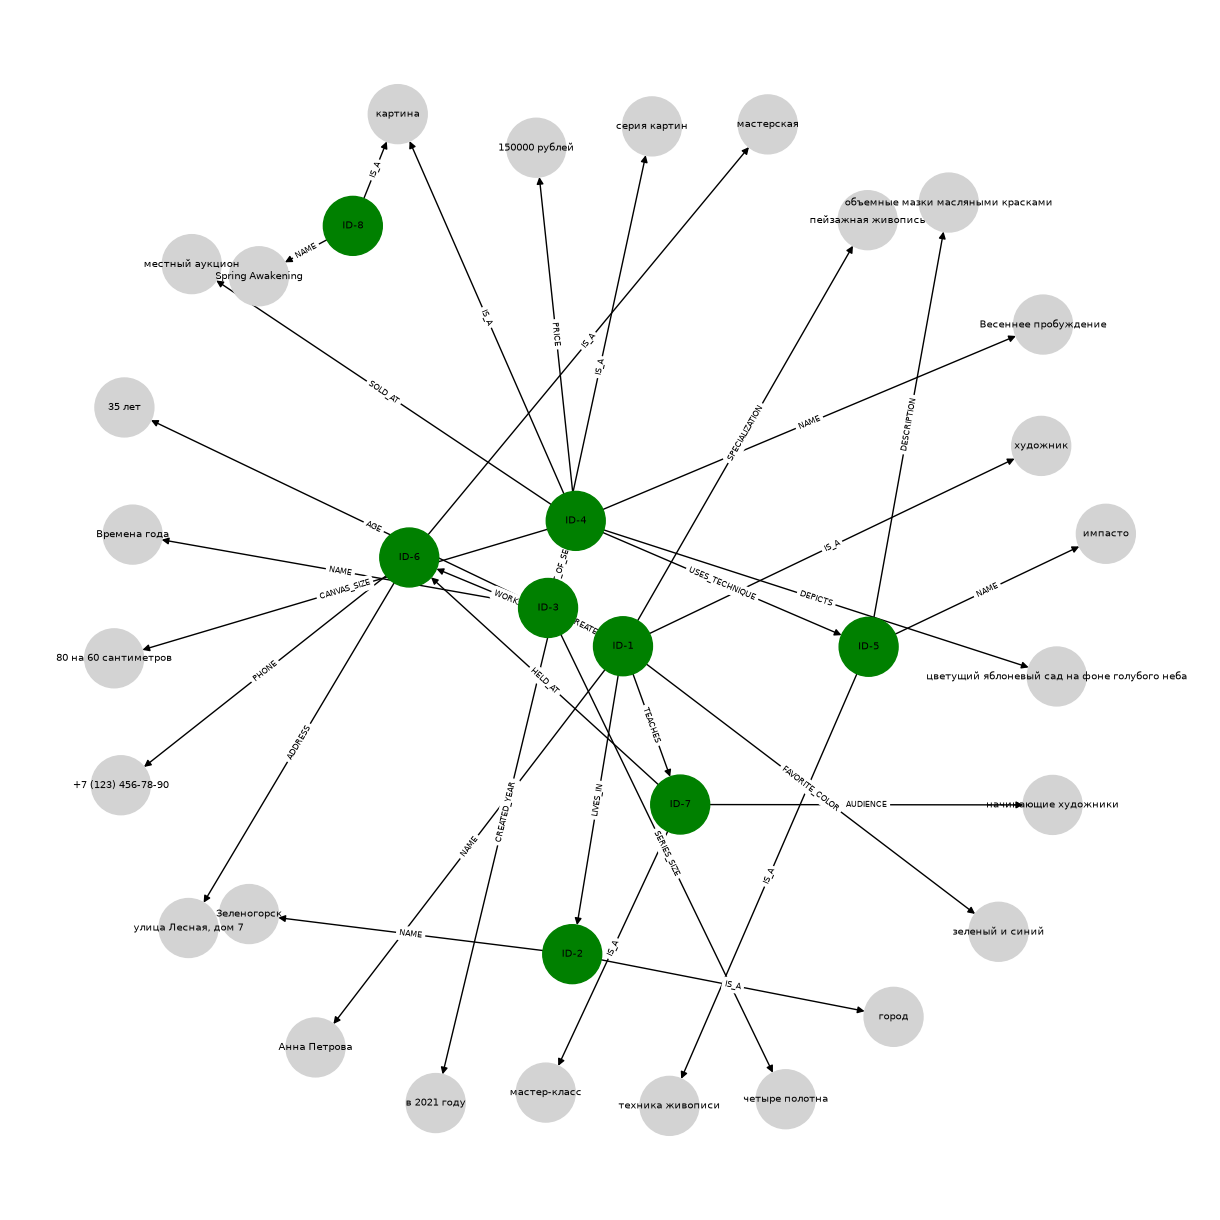

In [73]:
draw_parse_graph(A)

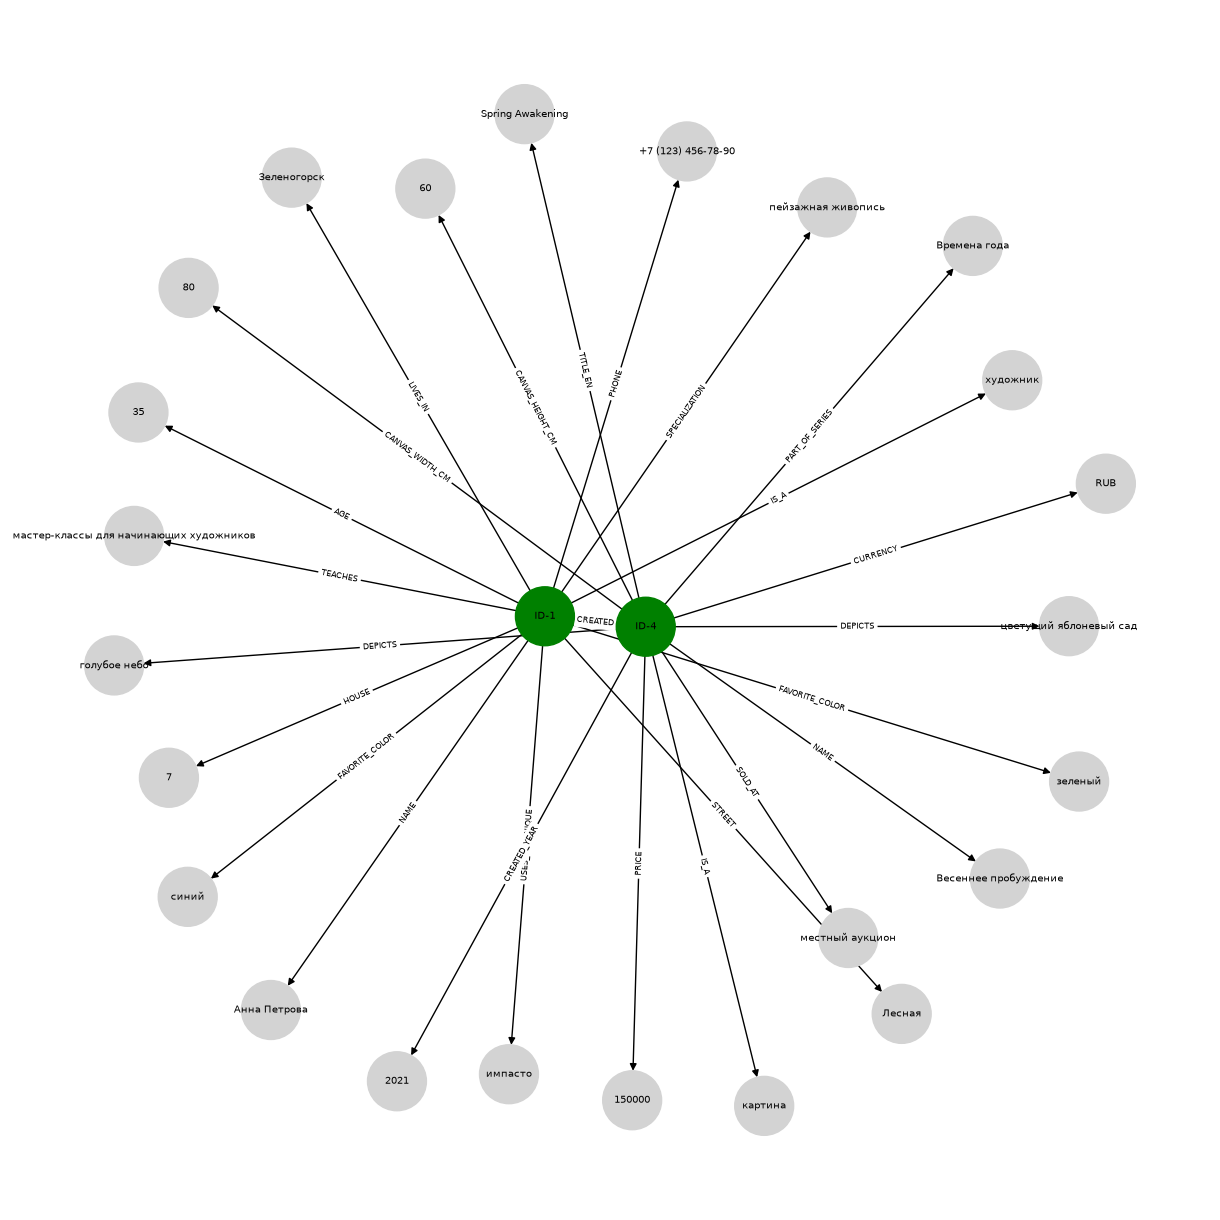

In [74]:
draw_parse_graph(B)

В разборе A больше нелитеральных узлов: город, серия картин, техника, мастерская и мастер-класс представлены отдельными сущностями. В разборе B большая часть этой информации записана непосредственно как литеральные свойства художницы или картины, поэтому граф B содержит меньше сущностей и имеет более плоскую структуру.

<p class="task" id="3"></p>

3\. Сериализуйте разбор B в формате `Turtle`. Для формирования URI используйте следующие правила:

* URI нелитерального объекта: `http://www.fa.ru/entity/{id}`, где `id` - числовая часть идентификатора сущности из разбора B. Пример: `http://www.fa.ru/entity/1`;
* URI предиката: `http://www.fa.ru/predicate/{type}`, где `type` - название отношения в нотации lowerCamelCase. Пример: `http://www.fa.ru/predicate/livesIn`.

Для строковых литералов укажите языковой тег, для нестроковых - URI типа данных. Объявите пространства имен директивой `@prefix`, используйте списки предикатов и списки объектов везде, где это возможно.

Результат представьте в виде строки `turtle` и выведите на экран.

Не используйте готовых решений для сериализации. Допускается автоматизированное формирование сериализованного представления при помощи собственных реализаций.

Проверьте результат в [ShExValidata](https://www.w3.org/2015/03/ShExValidata/) и вставьте в ноутбук скриншот с подтверждением корректности.

- [ ] Проверено на семинаре

In [75]:
def to_camel_case(name):
    parts = name.lower().split("_")

    result = parts[0]

    for part in parts[1:]:
        result += part.capitalize()

    return result


def make_literal(relation, value):
    value = value.replace("\\", "\\\\")
    value = value.replace('"', '\\"')

    if relation in [
        Relation.AGE,
        Relation.CANVAS_WIDTH_CM,
        Relation.CANVAS_HEIGHT_CM,
        Relation.PRICE
    ]:
        return f'"{value}"^^xsd:integer'

    if relation == Relation.CREATED_YEAR:
        return f'"{value}"^^xsd:gYear'

    if relation == Relation.TITLE_EN:
        return f'"{value}"@en'

    if relation == Relation.CURRENCY:
        return f'"{value}"@en'

    return f'"{value}"@ru'


grouped = {}

for subject, relation, obj in PARSE_B:
    if subject not in grouped:
        grouped[subject] = {}

    if relation not in grouped[subject]:
        grouped[subject][relation] = []

    grouped[subject][relation].append(obj)


lines = [
    "@prefix e: <http://www.fa.ru/entity/> .",
    "@prefix p: <http://www.fa.ru/predicate/> .",
    "@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .",
    ""
]


for subject, relations in grouped.items():
    subject_id = subject.split("-")[1]

    lines.append(f"e:{subject_id}")

    relation_items = list(relations.items())

    for i, (relation, objects_list) in enumerate(relation_items):
        predicate = to_camel_case(relation.name)

        values = []

        for obj in objects_list:
            if obj.startswith("ID-"):
                obj_id = obj.split("-")[1]
                values.append(f"e:{obj_id}")
            else:
                values.append(make_literal(relation, obj))

        values_text = ", ".join(values)

        if i == len(relation_items) - 1:
            end = " ."
        else:
            end = " ;"

        lines.append(
            f"    p:{predicate} {values_text}{end}"
        )

    lines.append("")


turtle = "\n".join(lines)

print(turtle)

@prefix e: <http://www.fa.ru/entity/> .
@prefix p: <http://www.fa.ru/predicate/> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .

e:1
    p:isA "художник"@ru ;
    p:name "Анна Петрова"@ru ;
    p:age "35"^^xsd:integer ;
    p:specialization "пейзажная живопись"@ru ;
    p:livesIn "Зеленогорск"@ru ;
    p:favoriteColor "зеленый"@ru, "синий"@ru ;
    p:created e:4 ;
    p:usesTechnique "импасто"@ru ;
    p:street "Лесная"@ru ;
    p:house "7"@ru ;
    p:phone "+7 (123) 456-78-90"@ru ;
    p:teaches "мастер-классы для начинающих художников"@ru .

e:4
    p:isA "картина"@ru ;
    p:name "Весеннее пробуждение"@ru ;
    p:titleEn "Spring Awakening"@en ;
    p:partOfSeries "Времена года"@ru ;
    p:createdYear "2021"^^xsd:gYear ;
    p:depicts "цветущий яблоневый сад"@ru, "голубое небо"@ru ;
    p:canvasWidthCm "80"^^xsd:integer ;
    p:canvasHeightCm "60"^^xsd:integer ;
    p:soldAt "местный аукцион"@ru ;
    p:price "150000"^^xsd:integer ;
    p:currency "RUB"@en .



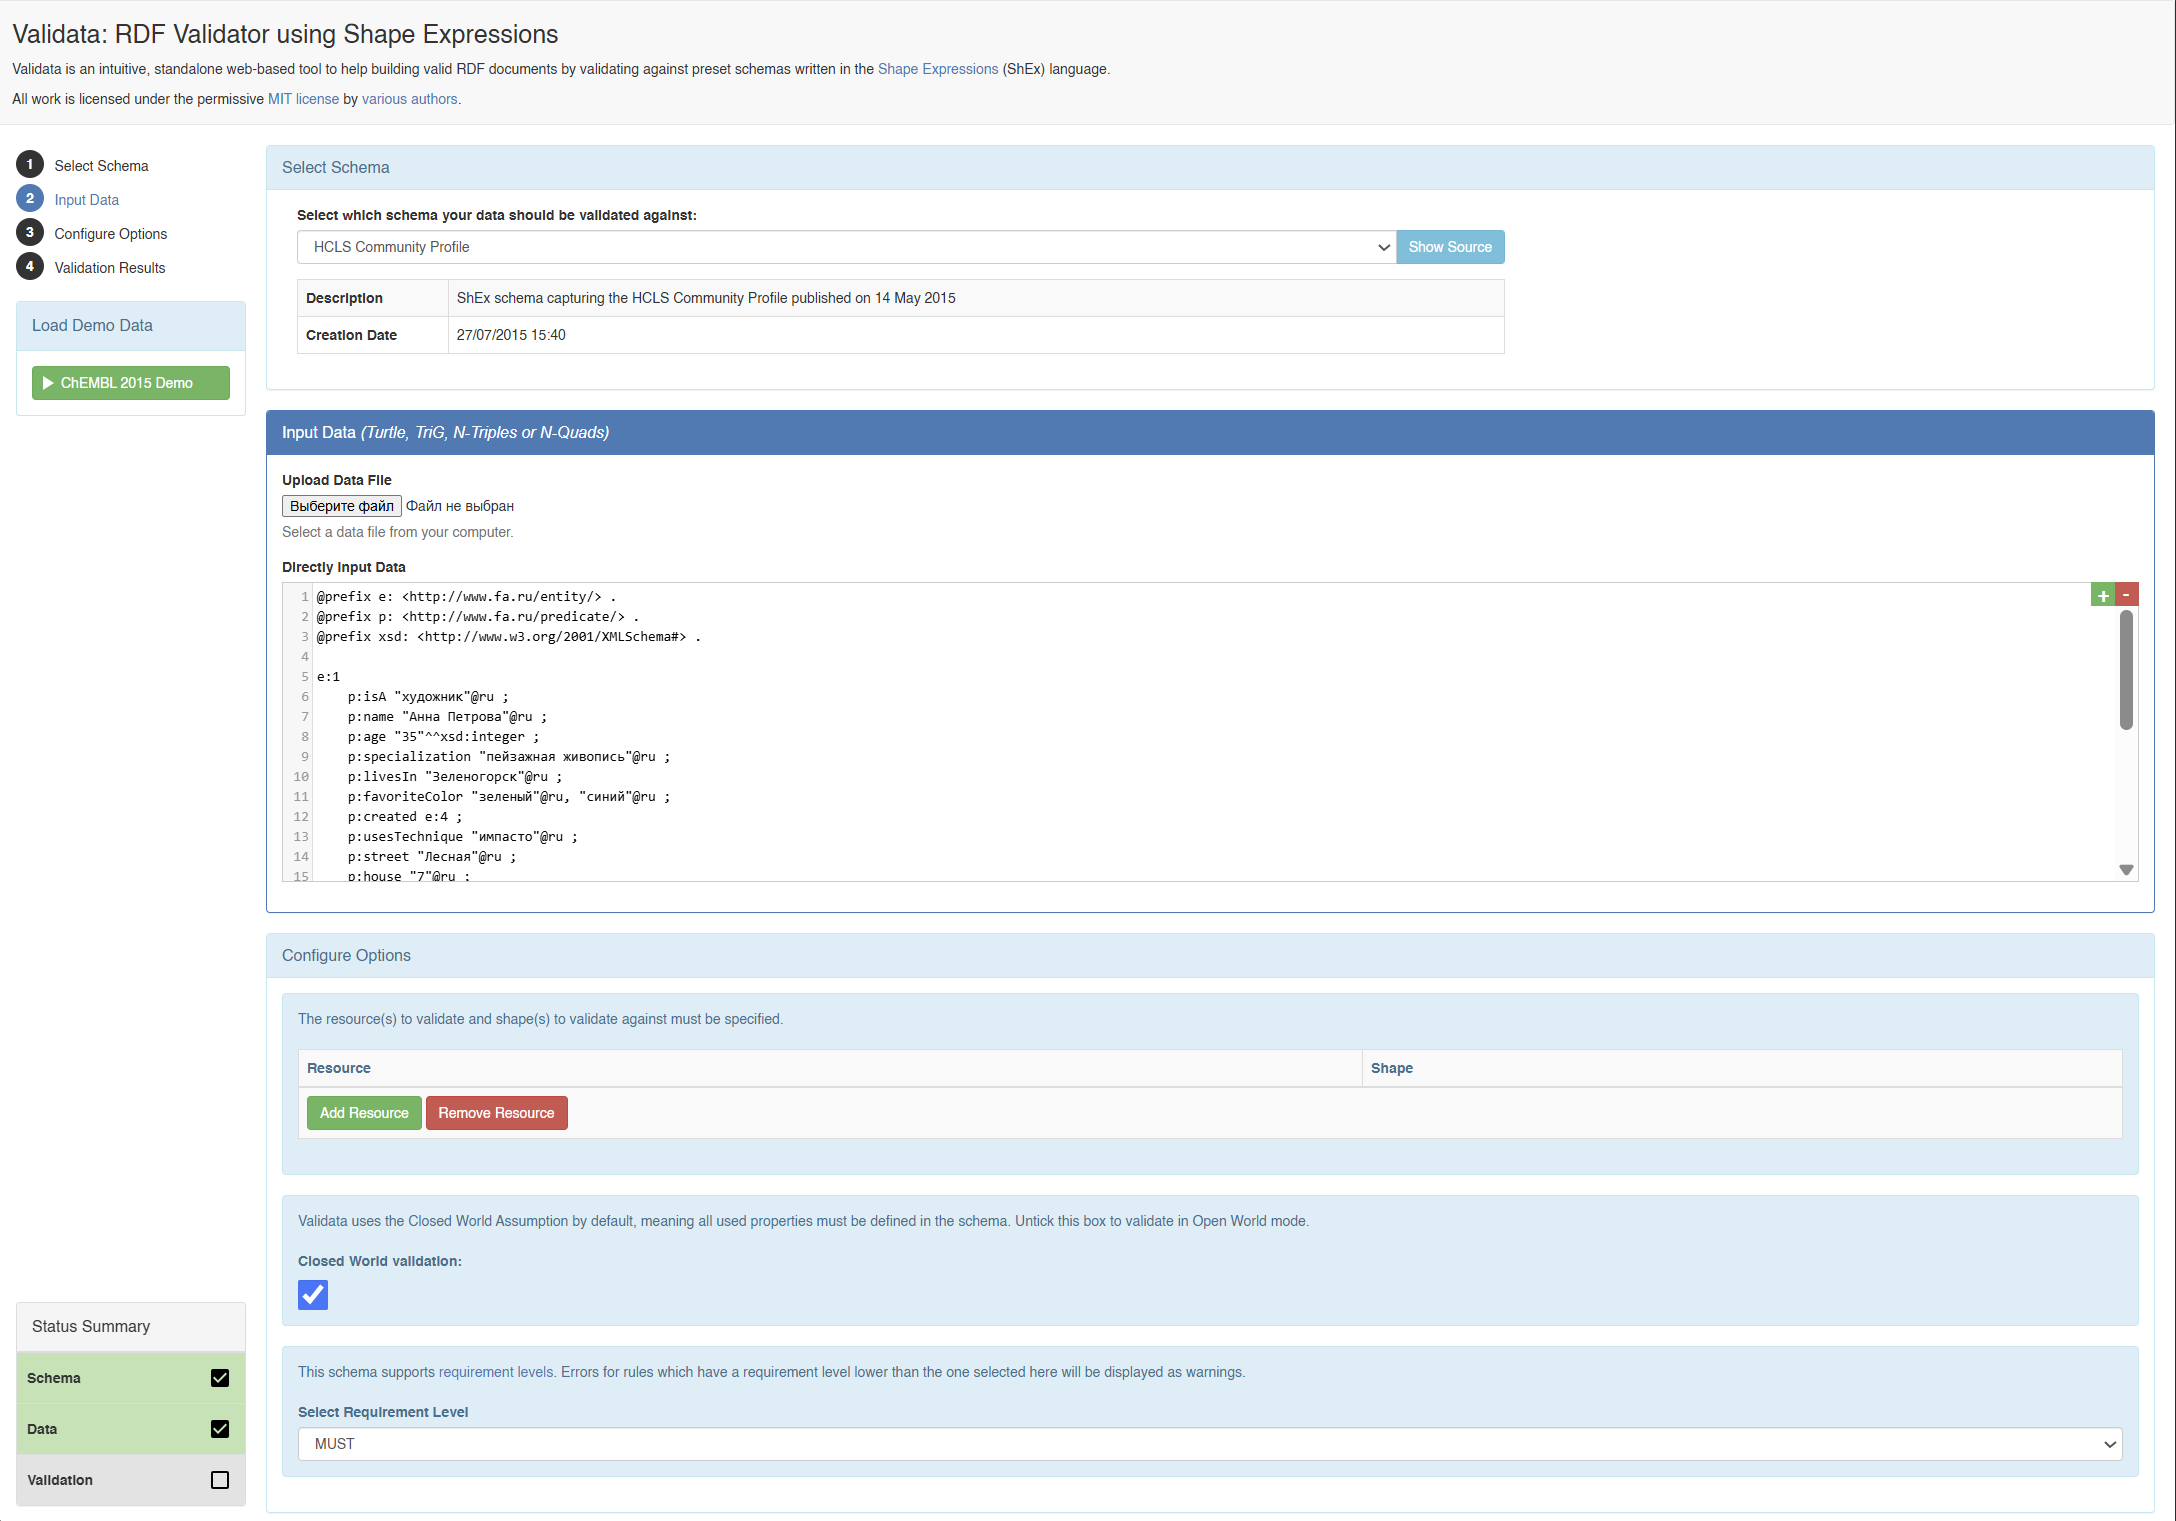

<p class="task" id="4"></p>

4\. В файле `data/python_versions.csv` даны основные версии Python с датой релиза и датой окончания полной поддержки. Требуется представить эти данные в виде RDF-графа, где субъектом выступает сущность Python, объектами - номера версий, а обе даты прикреплены к утверждениям как квалификаторы.

Выполните материализацию по схеме 2 и сериализуйте результат в формате `Turtle`. Используйте пространства имен, приведенные в разборе схемы 2. Для узлов-утверждений сгенерируйте уникальные идентификаторы, например при помощи [uuid](https://docs.python.org/3/library/uuid.html).

Обратите внимание, что часть дат известна с точностью до месяца - укажите для таких литералов тип `xsd:gYearMonth`, для остальных `xsd:date`.

Результат представьте в виде строки `pythonVersionsV2`. Выведите ее на экран, а также количество троек в полученном графе. Отдельно выведите список версий, попавших в граф, и убедитесь, что их 15 и что они различны.

Проверьте результат в [ShExValidata](https://www.w3.org/2015/03/ShExValidata/) и вставьте в ноутбук скриншот с подтверждением корректности. К следующему заданию переходите только после того, как проверка пройдена.

- [ ] Проверено на семинаре

In [76]:
import pandas as pd
import uuid


python_df = pd.read_csv("data/python_versions.csv", dtype=str)
python_df


,version,release_date,end_of_full_support
0,3.0,2008-12-03,2009-06-27
1,3.1,2009-06-27,2011-06-12
2,3.2,2011-02-20,2013-05-13
3,3.3,2012-09-29,2014-03-08
4,3.4,2014-03-16,2017-08-09
5,3.5,2015-09-13,2017-08-08
6,3.6,2016-12-23,2018-12-24
7,3.7,2018-06-27,2020-06-27
8,3.8,2019-10-14,2021-05-03
9,3.9,2020-10-05,2022-05-17


In [77]:
def date_literal(value):
    value = value.strip()

    if re.fullmatch(r"\d{4}-\d{2}", value):
        return f'"{value}"^^xsd:gYearMonth'

    return f'"{value}"^^xsd:date'


lines = [
    "@prefix e: <http://www.fa.ru/entity/> .",
    "@prefix p: <http://www.fa.ru/prop/> .",
    "@prefix ps: <http://www.fa.ru/prop/statement/> .",
    "@prefix pq: <http://www.fa.ru/prop/qualifier/> .",
    "@prefix s: <http://www.fa.ru/entity/statement/> .",
    "@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .",
    ""
]


versions = []
triple_count = 0


for _, row in python_df.iterrows():
    version = row["version"].strip()
    release_date = row["release_date"].strip()
    end_of_full_support = row["end_of_full_support"].strip()

    statement_id = "a" + uuid.uuid4().hex

    lines.append(
        f"e:Python p:version s:{statement_id} ."
    )

    lines.append("")

    lines.append(
        f's:{statement_id} ps:version "{version}" ;'
    )

    lines.append(
        f"    pq:releaseDate {date_literal(release_date)} ;"
    )

    lines.append(
        f"    pq:fullSupportEnd {date_literal(end_of_full_support)} ."
    )

    lines.append("")

    versions.append(version)

    triple_count += 4


pythonVersionsV2 = "\n".join(lines)


print(pythonVersionsV2)

@prefix e: <http://www.fa.ru/entity/> .
@prefix p: <http://www.fa.ru/prop/> .
@prefix ps: <http://www.fa.ru/prop/statement/> .
@prefix pq: <http://www.fa.ru/prop/qualifier/> .
@prefix s: <http://www.fa.ru/entity/statement/> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .

e:Python p:version s:a8526512d68694fbbab7f0d55971a773b .

s:a8526512d68694fbbab7f0d55971a773b ps:version "3.0" ;
    pq:releaseDate "2008-12-03"^^xsd:date ;
    pq:fullSupportEnd "2009-06-27"^^xsd:date .

e:Python p:version s:a1a29b2c94536452fa11a09024e3017f7 .

s:a1a29b2c94536452fa11a09024e3017f7 ps:version "3.1" ;
    pq:releaseDate "2009-06-27"^^xsd:date ;
    pq:fullSupportEnd "2011-06-12"^^xsd:date .

e:Python p:version s:a069c6760598f4da885a7e65e4e713323 .

s:a069c6760598f4da885a7e65e4e713323 ps:version "3.2" ;
    pq:releaseDate "2011-02-20"^^xsd:date ;
    pq:fullSupportEnd "2013-05-13"^^xsd:date .

e:Python p:version s:a64b0ccf990be42ddae96263dda04be46 .

s:a64b0ccf990be42ddae96263dda04be46 ps:version "3

In [78]:

print("Количество троек:", triple_count)

print("Версии:")
print(versions)

print("Количество версий:", len(versions))
print("Количество различных версий:", len(set(versions)))


assert len(versions) == 15
assert len(set(versions)) == 15

Количество троек: 60
Версии:
['3.0', '3.1', '3.2', '3.3', '3.4', '3.5', '3.6', '3.7', '3.8', '3.9', '3.10', '3.11', '3.12', '3.13', '3.14']
Количество версий: 15
Количество различных версий: 15


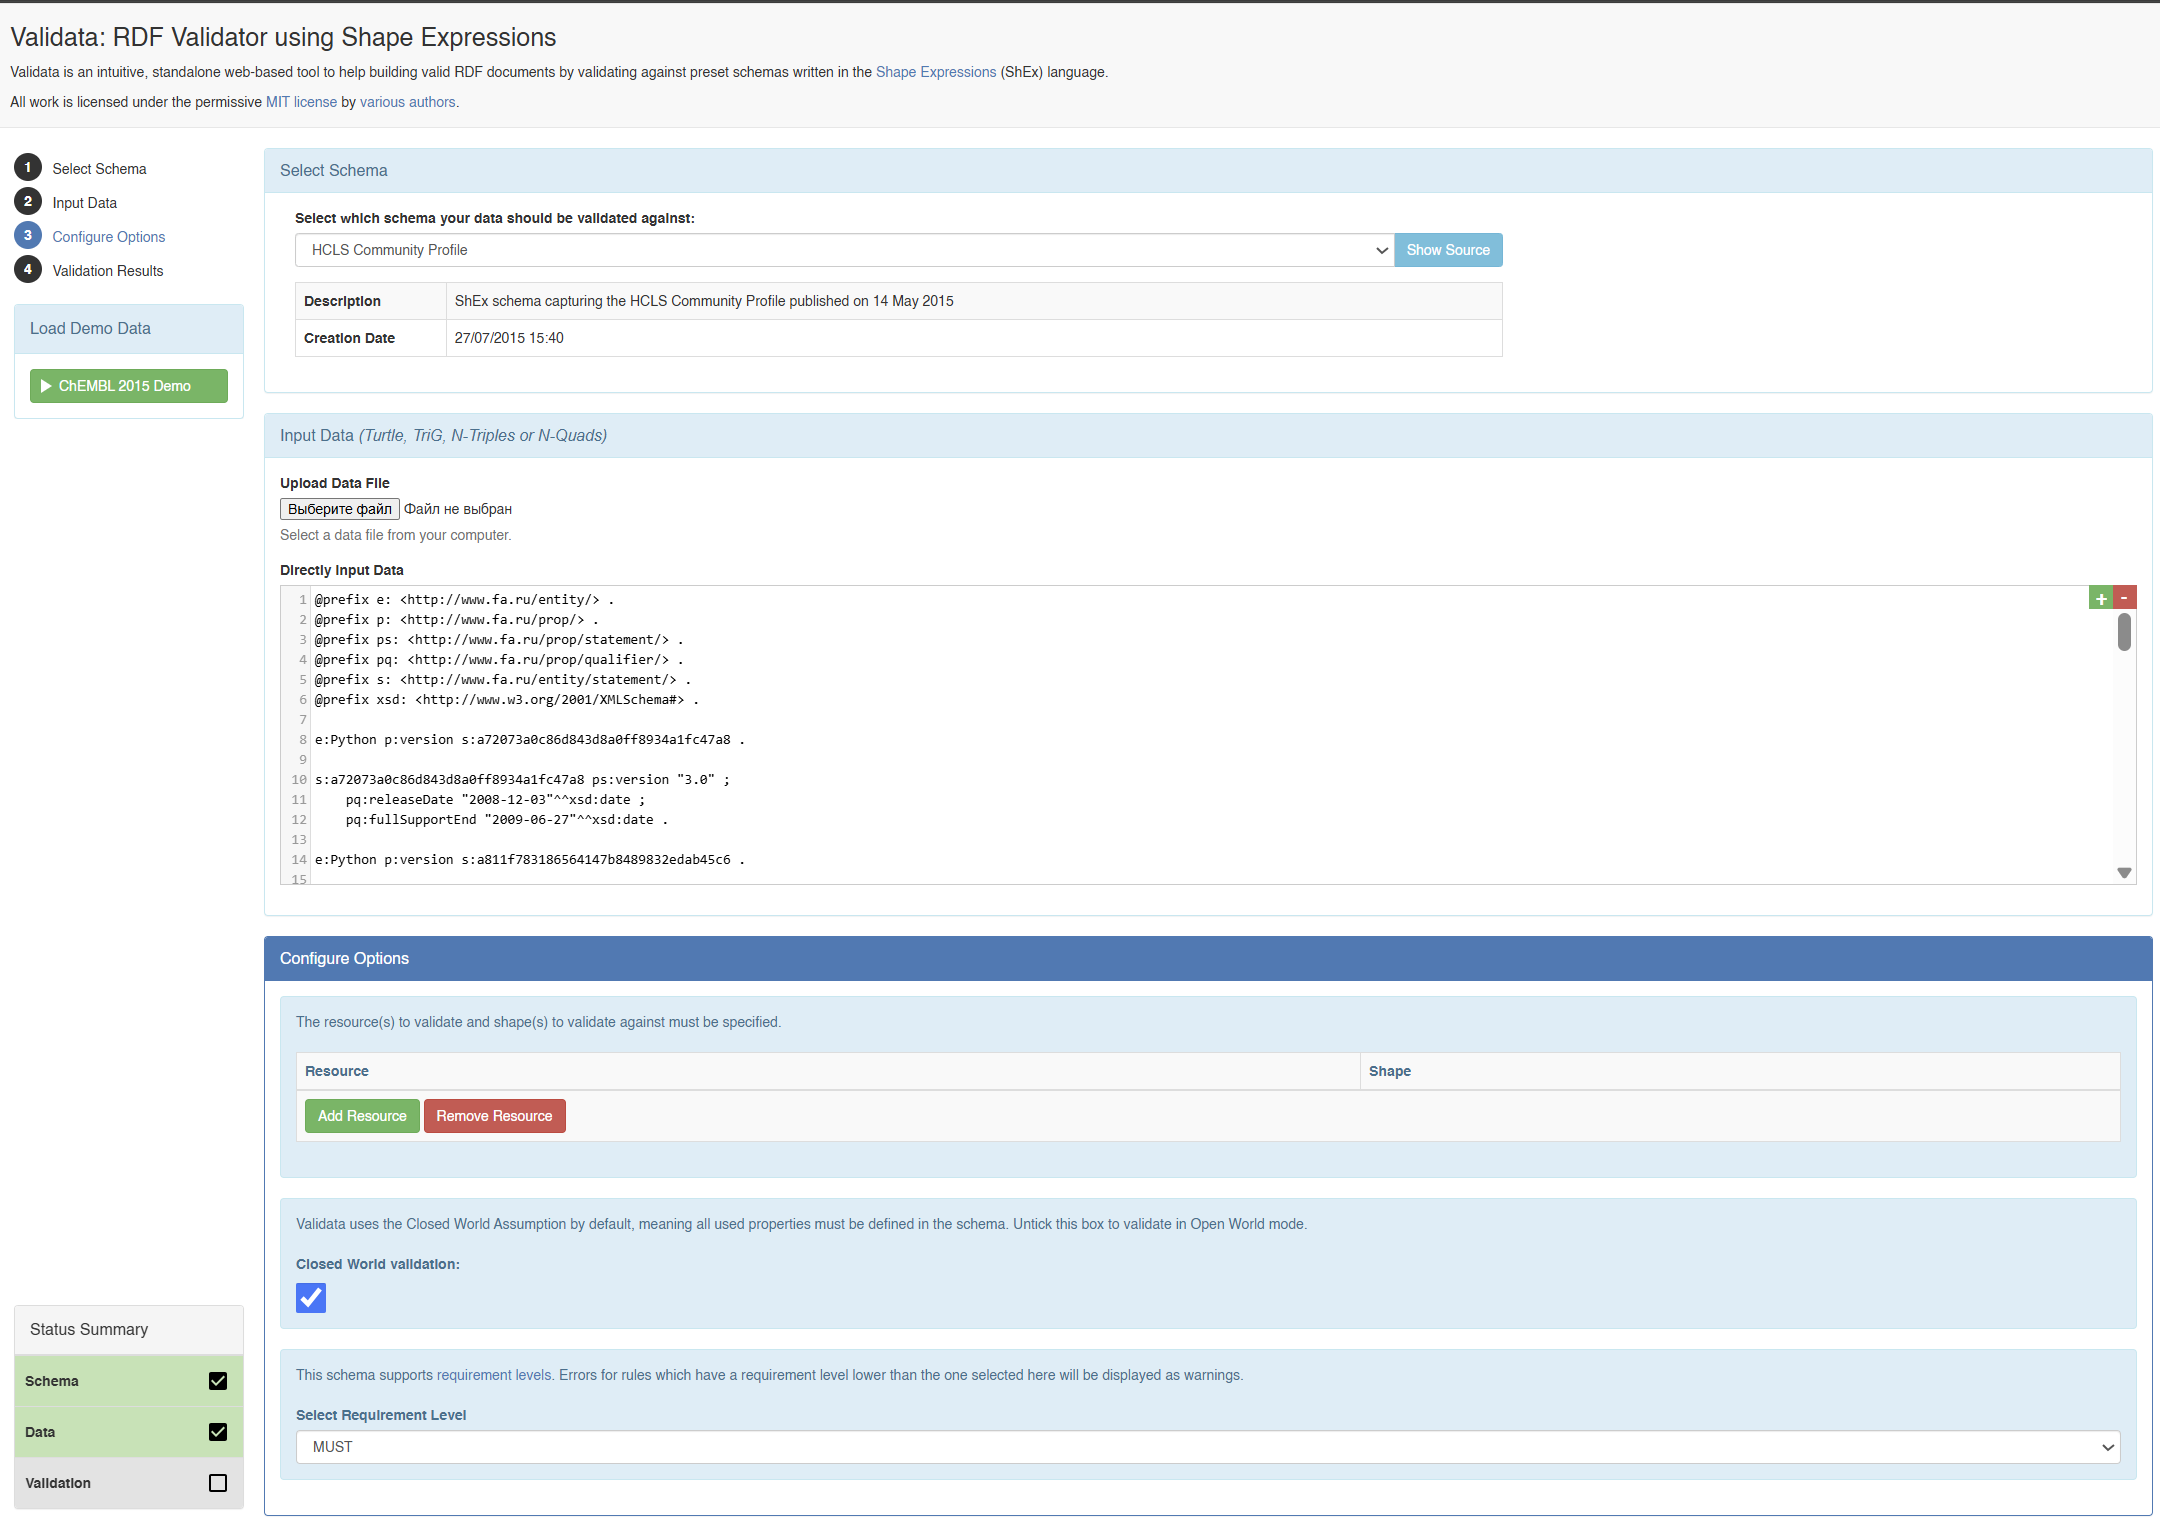

<p class="task" id="5"></p>

5\. Возьмите строку `pythonVersionsV2` из задания 4, прошедшую проверку валидатором, и преобразуйте ее в форматы `N-Triples` и `JSON-LD` при помощи [конвертера isSemantic](https://issemantic.net/rdf-converter).

Вставьте оба результата в ноутбук текстовыми ячейками.

В текстовой ячейке сделайте выводы о том, как меняется количество строк при переходе от `Turtle` к `N-Triples` и к `JSON-LD`.

- [ ] Проверено на семинаре

In [79]:
n_triples = """<http://www.fa.ru/entity/Python> <http://www.fa.ru/prop/version> <http://www.fa.ru/entity/statement/ab6e598314896451483a1ba5d1c1493da> .
<http://www.fa.ru/entity/statement/a33c29bc9534d47f6a7950e6a00b2b44b> <http://www.fa.ru/prop/qualifier/releaseDate> "2009-06-27"^^<http://www.w3.org/2001/XMLSchema#date> .
<http://www.fa.ru/entity/statement/a2450bbe159f1441489e5ca3a4d42c74c> <http://www.fa.ru/prop/qualifier/releaseDate> "2024-10-07"^^<http://www.w3.org/2001/XMLSchema#date> .
<http://www.fa.ru/entity/Python> <http://www.fa.ru/prop/version> <http://www.fa.ru/entity/statement/af4fe4ca3cfca45dc9f0afc2f4cfc2c0e> .
<http://www.fa.ru/entity/statement/ac162a25ba88f4c468377b9589ac2d1eb> <http://www.fa.ru/prop/qualifier/fullSupportEnd> "2013-05-13"^^<http://www.w3.org/2001/XMLSchema#date> .
<http://www.fa.ru/entity/Python> <http://www.fa.ru/prop/version> <http://www.fa.ru/entity/statement/aa1a297aac3844055bec5a8a0fabecbcd> .
<http://www.fa.ru/entity/Python> <http://www.fa.ru/prop/version> <http://www.fa.ru/entity/statement/a2450bbe159f1441489e5ca3a4d42c74c> .
<http://www.fa.ru/entity/statement/af4fe4ca3cfca45dc9f0afc2f4cfc2c0e> <http://www.fa.ru/prop/qualifier/fullSupportEnd> "2023-04-05"^^<http://www.w3.org/2001/XMLSchema#date> .
<http://www.fa.ru/entity/statement/ac162a25ba88f4c468377b9589ac2d1eb> <http://www.fa.ru/prop/statement/version> "3.2" .
<http://www.fa.ru/entity/statement/ab6e598314896451483a1ba5d1c1493da> <http://www.fa.ru/prop/qualifier/releaseDate> "2022-10-24"^^<http://www.w3.org/2001/XMLSchema#date> .
<http://www.fa.ru/entity/statement/aa1a297aac3844055bec5a8a0fabecbcd> <http://www.fa.ru/prop/statement/version> "3.0" .
<http://www.fa.ru/entity/Python> <http://www.fa.ru/prop/version> <http://www.fa.ru/entity/statement/ae1b370fffd3946ae9099be5c6463f192> .
<http://www.fa.ru/entity/statement/ae990a04d2bf741d6b7ec6cc3a7b5867d> <http://www.fa.ru/prop/qualifier/fullSupportEnd> "2027-10-01"^^<http://www.w3.org/2001/XMLSchema#gYearMonth> .
<http://www.fa.ru/entity/Python> <http://www.fa.ru/prop/version> <http://www.fa.ru/entity/statement/ae990a04d2bf741d6b7ec6cc3a7b5867d> .
<http://www.fa.ru/entity/statement/a33c29bc9534d47f6a7950e6a00b2b44b> <http://www.fa.ru/prop/qualifier/fullSupportEnd> "2011-06-12"^^<http://www.w3.org/2001/XMLSchema#date> .
<http://www.fa.ru/entity/statement/af8d88a4a052d4151a70e5c9c28a5380d> <http://www.fa.ru/prop/qualifier/releaseDate> "2015-09-13"^^<http://www.w3.org/2001/XMLSchema#date> .
<http://www.fa.ru/entity/statement/a13ad572ebcfd4d6385e89e7f7709dcc3> <http://www.fa.ru/prop/statement/version> "3.12" .
<http://www.fa.ru/entity/statement/ac162a25ba88f4c468377b9589ac2d1eb> <http://www.fa.ru/prop/qualifier/releaseDate> "2011-02-20"^^<http://www.w3.org/2001/XMLSchema#date> .
<http://www.fa.ru/entity/statement/ae990a04d2bf741d6b7ec6cc3a7b5867d> <http://www.fa.ru/prop/statement/version> "3.14" .
<http://www.fa.ru/entity/statement/a13ad572ebcfd4d6385e89e7f7709dcc3> <http://www.fa.ru/prop/qualifier/releaseDate> "2023-10-02"^^<http://www.w3.org/2001/XMLSchema#date> .
<http://www.fa.ru/entity/statement/a13ad572ebcfd4d6385e89e7f7709dcc3> <http://www.fa.ru/prop/qualifier/fullSupportEnd> "2025-04-08"^^<http://www.w3.org/2001/XMLSchema#date> .
<http://www.fa.ru/entity/statement/ae1b370fffd3946ae9099be5c6463f192> <http://www.fa.ru/prop/qualifier/releaseDate> "2016-12-23"^^<http://www.w3.org/2001/XMLSchema#date> .
<http://www.fa.ru/entity/statement/af4fe4ca3cfca45dc9f0afc2f4cfc2c0e> <http://www.fa.ru/prop/qualifier/releaseDate> "2021-10-04"^^<http://www.w3.org/2001/XMLSchema#date> .
<http://www.fa.ru/entity/statement/a54fe5d45f8b64d469b3d62e4cf21ecff> <http://www.fa.ru/prop/statement/version> "3.3" .
<http://www.fa.ru/entity/statement/a085afadce4f542d4a9b5f23fc1222ee5> <http://www.fa.ru/prop/qualifier/releaseDate> "2019-10-14"^^<http://www.w3.org/2001/XMLSchema#date> .
<http://www.fa.ru/entity/Python> <http://www.fa.ru/prop/version> <http://www.fa.ru/entity/statement/a085afadce4f542d4a9b5f23fc1222ee5> .
<http://www.fa.ru/entity/statement/ad49976fd70d844baae8ab7a077886082> <http://www.fa.ru/prop/qualifier/fullSupportEnd> "2020-06-27"^^<http://www.w3.org/2001/XMLSchema#date> .
<http://www.fa.ru/entity/statement/a04a498fd30334aa9847ccddf160ce7c2> <http://www.fa.ru/prop/qualifier/releaseDate> "2014-03-16"^^<http://www.w3.org/2001/XMLSchema#date> .
<http://www.fa.ru/entity/statement/af8d88a4a052d4151a70e5c9c28a5380d> <http://www.fa.ru/prop/qualifier/fullSupportEnd> "2017-08-08"^^<http://www.w3.org/2001/XMLSchema#date> .
<http://www.fa.ru/entity/statement/ab6e598314896451483a1ba5d1c1493da> <http://www.fa.ru/prop/statement/version> "3.11" .
<http://www.fa.ru/entity/Python> <http://www.fa.ru/prop/version> <http://www.fa.ru/entity/statement/a04a498fd30334aa9847ccddf160ce7c2> .
<http://www.fa.ru/entity/Python> <http://www.fa.ru/prop/version> <http://www.fa.ru/entity/statement/ad49976fd70d844baae8ab7a077886082> .
<http://www.fa.ru/entity/statement/aa1a297aac3844055bec5a8a0fabecbcd> <http://www.fa.ru/prop/qualifier/fullSupportEnd> "2009-06-27"^^<http://www.w3.org/2001/XMLSchema#date> .
<http://www.fa.ru/entity/statement/ae1b370fffd3946ae9099be5c6463f192> <http://www.fa.ru/prop/statement/version> "3.6" .
<http://www.fa.ru/entity/statement/af4fe4ca3cfca45dc9f0afc2f4cfc2c0e> <http://www.fa.ru/prop/statement/version> "3.10" .
<http://www.fa.ru/entity/statement/a54fe5d45f8b64d469b3d62e4cf21ecff> <http://www.fa.ru/prop/qualifier/fullSupportEnd> "2014-03-08"^^<http://www.w3.org/2001/XMLSchema#date> .
<http://www.fa.ru/entity/statement/a085afadce4f542d4a9b5f23fc1222ee5> <http://www.fa.ru/prop/qualifier/fullSupportEnd> "2021-05-03"^^<http://www.w3.org/2001/XMLSchema#date> .
<http://www.fa.ru/entity/statement/a04a498fd30334aa9847ccddf160ce7c2> <http://www.fa.ru/prop/qualifier/fullSupportEnd> "2017-08-09"^^<http://www.w3.org/2001/XMLSchema#date> .
<http://www.fa.ru/entity/statement/ab6e598314896451483a1ba5d1c1493da> <http://www.fa.ru/prop/qualifier/fullSupportEnd> "2024-04-02"^^<http://www.w3.org/2001/XMLSchema#date> .
<http://www.fa.ru/entity/statement/aa1a297aac3844055bec5a8a0fabecbcd> <http://www.fa.ru/prop/qualifier/releaseDate> "2008-12-03"^^<http://www.w3.org/2001/XMLSchema#date> .
<http://www.fa.ru/entity/statement/af8d88a4a052d4151a70e5c9c28a5380d> <http://www.fa.ru/prop/statement/version> "3.5" .
<http://www.fa.ru/entity/statement/adc549fb074b44c4cb03823cc979eaa69> <http://www.fa.ru/prop/qualifier/fullSupportEnd> "2022-05-17"^^<http://www.w3.org/2001/XMLSchema#date> .
<http://www.fa.ru/entity/statement/ad49976fd70d844baae8ab7a077886082> <http://www.fa.ru/prop/statement/version> "3.7" .
<http://www.fa.ru/entity/statement/ad49976fd70d844baae8ab7a077886082> <http://www.fa.ru/prop/qualifier/releaseDate> "2018-06-27"^^<http://www.w3.org/2001/XMLSchema#date> .
<http://www.fa.ru/entity/Python> <http://www.fa.ru/prop/version> <http://www.fa.ru/entity/statement/af8d88a4a052d4151a70e5c9c28a5380d> .
<http://www.fa.ru/entity/Python> <http://www.fa.ru/prop/version> <http://www.fa.ru/entity/statement/adc549fb074b44c4cb03823cc979eaa69> .
<http://www.fa.ru/entity/statement/ae990a04d2bf741d6b7ec6cc3a7b5867d> <http://www.fa.ru/prop/qualifier/releaseDate> "2025-10-07"^^<http://www.w3.org/2001/XMLSchema#date> .
<http://www.fa.ru/entity/statement/a04a498fd30334aa9847ccddf160ce7c2> <http://www.fa.ru/prop/statement/version> "3.4" .
<http://www.fa.ru/entity/statement/a085afadce4f542d4a9b5f23fc1222ee5> <http://www.fa.ru/prop/statement/version> "3.8" .
<http://www.fa.ru/entity/statement/a33c29bc9534d47f6a7950e6a00b2b44b> <http://www.fa.ru/prop/statement/version> "3.1" .
<http://www.fa.ru/entity/statement/adc549fb074b44c4cb03823cc979eaa69> <http://www.fa.ru/prop/statement/version> "3.9" .
<http://www.fa.ru/entity/statement/a2450bbe159f1441489e5ca3a4d42c74c> <http://www.fa.ru/prop/qualifier/fullSupportEnd> "2026-10-01"^^<http://www.w3.org/2001/XMLSchema#gYearMonth> .
<http://www.fa.ru/entity/Python> <http://www.fa.ru/prop/version> <http://www.fa.ru/entity/statement/a33c29bc9534d47f6a7950e6a00b2b44b> .
<http://www.fa.ru/entity/Python> <http://www.fa.ru/prop/version> <http://www.fa.ru/entity/statement/a13ad572ebcfd4d6385e89e7f7709dcc3> .
<http://www.fa.ru/entity/statement/a54fe5d45f8b64d469b3d62e4cf21ecff> <http://www.fa.ru/prop/qualifier/releaseDate> "2012-09-29"^^<http://www.w3.org/2001/XMLSchema#date> .
<http://www.fa.ru/entity/Python> <http://www.fa.ru/prop/version> <http://www.fa.ru/entity/statement/ac162a25ba88f4c468377b9589ac2d1eb> .
<http://www.fa.ru/entity/statement/adc549fb074b44c4cb03823cc979eaa69> <http://www.fa.ru/prop/qualifier/releaseDate> "2020-10-05"^^<http://www.w3.org/2001/XMLSchema#date> .
<http://www.fa.ru/entity/Python> <http://www.fa.ru/prop/version> <http://www.fa.ru/entity/statement/a54fe5d45f8b64d469b3d62e4cf21ecff> .
<http://www.fa.ru/entity/statement/a2450bbe159f1441489e5ca3a4d42c74c> <http://www.fa.ru/prop/statement/version> "3.13" .
<http://www.fa.ru/entity/statement/ae1b370fffd3946ae9099be5c6463f192> <http://www.fa.ru/prop/qualifier/fullSupportEnd> "2018-12-24"^^<http://www.w3.org/2001/XMLSchema#date> .
"""
json_ld = """[
  {
    "@id": "http://www.fa.ru/entity/statement/ad49976fd70d844baae8ab7a077886082",
    "http://www.fa.ru/prop/qualifier/fullSupportEnd": [
      {
        "@type": "http://www.w3.org/2001/XMLSchema#date",
        "@value": "2020-06-27"
      }
    ],
    "http://www.fa.ru/prop/qualifier/releaseDate": [
      {
        "@type": "http://www.w3.org/2001/XMLSchema#date",
        "@value": "2018-06-27"
      }
    ],
    "http://www.fa.ru/prop/statement/version": [
      {
        "@value": "3.7"
      }
    ]
  },
  {
    "@id": "http://www.fa.ru/entity/statement/af8d88a4a052d4151a70e5c9c28a5380d",
    "http://www.fa.ru/prop/qualifier/fullSupportEnd": [
      {
        "@type": "http://www.w3.org/2001/XMLSchema#date",
        "@value": "2017-08-08"
      }
    ],
    "http://www.fa.ru/prop/qualifier/releaseDate": [
      {
        "@type": "http://www.w3.org/2001/XMLSchema#date",
        "@value": "2015-09-13"
      }
    ],
    "http://www.fa.ru/prop/statement/version": [
      {
        "@value": "3.5"
      }
    ]
  },
  {
    "@id": "http://www.fa.ru/entity/statement/ac162a25ba88f4c468377b9589ac2d1eb",
    "http://www.fa.ru/prop/qualifier/fullSupportEnd": [
      {
        "@type": "http://www.w3.org/2001/XMLSchema#date",
        "@value": "2013-05-13"
      }
    ],
    "http://www.fa.ru/prop/qualifier/releaseDate": [
      {
        "@type": "http://www.w3.org/2001/XMLSchema#date",
        "@value": "2011-02-20"
      }
    ],
    "http://www.fa.ru/prop/statement/version": [
      {
        "@value": "3.2"
      }
    ]
  },
  {
    "@id": "http://www.fa.ru/entity/statement/ab6e598314896451483a1ba5d1c1493da",
    "http://www.fa.ru/prop/qualifier/fullSupportEnd": [
      {
        "@type": "http://www.w3.org/2001/XMLSchema#date",
        "@value": "2024-04-02"
      }
    ],
    "http://www.fa.ru/prop/qualifier/releaseDate": [
      {
        "@type": "http://www.w3.org/2001/XMLSchema#date",
        "@value": "2022-10-24"
      }
    ],
    "http://www.fa.ru/prop/statement/version": [
      {
        "@value": "3.11"
      }
    ]
  },
  {
    "@id": "http://www.fa.ru/entity/statement/ae990a04d2bf741d6b7ec6cc3a7b5867d",
    "http://www.fa.ru/prop/qualifier/fullSupportEnd": [
      {
        "@type": "http://www.w3.org/2001/XMLSchema#gYearMonth",
        "@value": "2027-10-01"
      }
    ],
    "http://www.fa.ru/prop/qualifier/releaseDate": [
      {
        "@type": "http://www.w3.org/2001/XMLSchema#date",
        "@value": "2025-10-07"
      }
    ],
    "http://www.fa.ru/prop/statement/version": [
      {
        "@value": "3.14"
      }
    ]
  },
  {
    "@id": "http://www.fa.ru/entity/statement/ae1b370fffd3946ae9099be5c6463f192",
    "http://www.fa.ru/prop/qualifier/fullSupportEnd": [
      {
        "@type": "http://www.w3.org/2001/XMLSchema#date",
        "@value": "2018-12-24"
      }
    ],
    "http://www.fa.ru/prop/qualifier/releaseDate": [
      {
        "@type": "http://www.w3.org/2001/XMLSchema#date",
        "@value": "2016-12-23"
      }
    ],
    "http://www.fa.ru/prop/statement/version": [
      {
        "@value": "3.6"
      }
    ]
  },
  {
    "@id": "http://www.fa.ru/entity/statement/a085afadce4f542d4a9b5f23fc1222ee5",
    "http://www.fa.ru/prop/qualifier/fullSupportEnd": [
      {
        "@type": "http://www.w3.org/2001/XMLSchema#date",
        "@value": "2021-05-03"
      }
    ],
    "http://www.fa.ru/prop/qualifier/releaseDate": [
      {
        "@type": "http://www.w3.org/2001/XMLSchema#date",
        "@value": "2019-10-14"
      }
    ],
    "http://www.fa.ru/prop/statement/version": [
      {
        "@value": "3.8"
      }
    ]
  },
  {
    "@id": "http://www.fa.ru/entity/statement/a33c29bc9534d47f6a7950e6a00b2b44b",
    "http://www.fa.ru/prop/qualifier/fullSupportEnd": [
      {
        "@type": "http://www.w3.org/2001/XMLSchema#date",
        "@value": "2011-06-12"
      }
    ],
    "http://www.fa.ru/prop/qualifier/releaseDate": [
      {
        "@type": "http://www.w3.org/2001/XMLSchema#date",
        "@value": "2009-06-27"
      }
    ],
    "http://www.fa.ru/prop/statement/version": [
      {
        "@value": "3.1"
      }
    ]
  },
  {
    "@id": "http://www.fa.ru/entity/statement/a54fe5d45f8b64d469b3d62e4cf21ecff",
    "http://www.fa.ru/prop/qualifier/fullSupportEnd": [
      {
        "@type": "http://www.w3.org/2001/XMLSchema#date",
        "@value": "2014-03-08"
      }
    ],
    "http://www.fa.ru/prop/qualifier/releaseDate": [
      {
        "@type": "http://www.w3.org/2001/XMLSchema#date",
        "@value": "2012-09-29"
      }
    ],
    "http://www.fa.ru/prop/statement/version": [
      {
        "@value": "3.3"
      }
    ]
  },
  {
    "@id": "http://www.fa.ru/entity/statement/a13ad572ebcfd4d6385e89e7f7709dcc3",
    "http://www.fa.ru/prop/qualifier/fullSupportEnd": [
      {
        "@type": "http://www.w3.org/2001/XMLSchema#date",
        "@value": "2025-04-08"
      }
    ],
    "http://www.fa.ru/prop/qualifier/releaseDate": [
      {
        "@type": "http://www.w3.org/2001/XMLSchema#date",
        "@value": "2023-10-02"
      }
    ],
    "http://www.fa.ru/prop/statement/version": [
      {
        "@value": "3.12"
      }
    ]
  },
  {
    "@id": "http://www.fa.ru/entity/statement/a04a498fd30334aa9847ccddf160ce7c2",
    "http://www.fa.ru/prop/qualifier/fullSupportEnd": [
      {
        "@type": "http://www.w3.org/2001/XMLSchema#date",
        "@value": "2017-08-09"
      }
    ],
    "http://www.fa.ru/prop/qualifier/releaseDate": [
      {
        "@type": "http://www.w3.org/2001/XMLSchema#date",
        "@value": "2014-03-16"
      }
    ],
    "http://www.fa.ru/prop/statement/version": [
      {
        "@value": "3.4"
      }
    ]
  },
  {
    "@id": "http://www.fa.ru/entity/statement/af4fe4ca3cfca45dc9f0afc2f4cfc2c0e",
    "http://www.fa.ru/prop/qualifier/fullSupportEnd": [
      {
        "@type": "http://www.w3.org/2001/XMLSchema#date",
        "@value": "2023-04-05"
      }
    ],
    "http://www.fa.ru/prop/qualifier/releaseDate": [
      {
        "@type": "http://www.w3.org/2001/XMLSchema#date",
        "@value": "2021-10-04"
      }
    ],
    "http://www.fa.ru/prop/statement/version": [
      {
        "@value": "3.10"
      }
    ]
  },
  {
    "@id": "http://www.fa.ru/entity/statement/a2450bbe159f1441489e5ca3a4d42c74c",
    "http://www.fa.ru/prop/qualifier/fullSupportEnd": [
      {
        "@type": "http://www.w3.org/2001/XMLSchema#gYearMonth",
        "@value": "2026-10-01"
      }
    ],
    "http://www.fa.ru/prop/qualifier/releaseDate": [
      {
        "@type": "http://www.w3.org/2001/XMLSchema#date",
        "@value": "2024-10-07"
      }
    ],
    "http://www.fa.ru/prop/statement/version": [
      {
        "@value": "3.13"
      }
    ]
  },
  {
    "@id": "http://www.fa.ru/entity/statement/aa1a297aac3844055bec5a8a0fabecbcd",
    "http://www.fa.ru/prop/qualifier/fullSupportEnd": [
      {
        "@type": "http://www.w3.org/2001/XMLSchema#date",
        "@value": "2009-06-27"
      }
    ],
    "http://www.fa.ru/prop/qualifier/releaseDate": [
      {
        "@type": "http://www.w3.org/2001/XMLSchema#date",
        "@value": "2008-12-03"
      }
    ],
    "http://www.fa.ru/prop/statement/version": [
      {
        "@value": "3.0"
      }
    ]
  },
  {
    "@id": "http://www.fa.ru/entity/statement/adc549fb074b44c4cb03823cc979eaa69",
    "http://www.fa.ru/prop/qualifier/fullSupportEnd": [
      {
        "@type": "http://www.w3.org/2001/XMLSchema#date",
        "@value": "2022-05-17"
      }
    ],
    "http://www.fa.ru/prop/qualifier/releaseDate": [
      {
        "@type": "http://www.w3.org/2001/XMLSchema#date",
        "@value": "2020-10-05"
      }
    ],
    "http://www.fa.ru/prop/statement/version": [
      {
        "@value": "3.9"
      }
    ]
  },
  {
    "@id": "http://www.fa.ru/entity/Python",
    "http://www.fa.ru/prop/version": [
      {
        "@id": "http://www.fa.ru/entity/statement/ad49976fd70d844baae8ab7a077886082"
      },
      {
        "@id": "http://www.fa.ru/entity/statement/af4fe4ca3cfca45dc9f0afc2f4cfc2c0e"
      },
      {
        "@id": "http://www.fa.ru/entity/statement/a085afadce4f542d4a9b5f23fc1222ee5"
      },
      {
        "@id": "http://www.fa.ru/entity/statement/ae1b370fffd3946ae9099be5c6463f192"
      },
      {
        "@id": "http://www.fa.ru/entity/statement/ab6e598314896451483a1ba5d1c1493da"
      },
      {
        "@id": "http://www.fa.ru/entity/statement/a2450bbe159f1441489e5ca3a4d42c74c"
      },
      {
        "@id": "http://www.fa.ru/entity/statement/a13ad572ebcfd4d6385e89e7f7709dcc3"
      },
      {
        "@id": "http://www.fa.ru/entity/statement/af8d88a4a052d4151a70e5c9c28a5380d"
      },
      {
        "@id": "http://www.fa.ru/entity/statement/aa1a297aac3844055bec5a8a0fabecbcd"
      },
      {
        "@id": "http://www.fa.ru/entity/statement/ae990a04d2bf741d6b7ec6cc3a7b5867d"
      },
      {
        "@id": "http://www.fa.ru/entity/statement/ac162a25ba88f4c468377b9589ac2d1eb"
      },
      {
        "@id": "http://www.fa.ru/entity/statement/a33c29bc9534d47f6a7950e6a00b2b44b"
      },
      {
        "@id": "http://www.fa.ru/entity/statement/a54fe5d45f8b64d469b3d62e4cf21ecff"
      },
      {
        "@id": "http://www.fa.ru/entity/statement/adc549fb074b44c4cb03823cc979eaa69"
      },
      {
        "@id": "http://www.fa.ru/entity/statement/a04a498fd30334aa9847ccddf160ce7c2"
      }
    ]
  }
]
"""

In [80]:
turtle_lines = pythonVersionsV2.count('\n')+1
n_triples_lines = n_triples.count('\n')+1
json_ld_lines = json_ld.count('\n')+1

print(f'При переходе от Turtle к N-Triples кол-во строчек {turtle_lines} -> {n_triples_lines} (-{(1 - n_triples_lines/turtle_lines )*100:.2f}%)')
print(f'При переходе от Turtle к JSON-LD кол-во строчек {turtle_lines} -> {json_ld_lines} (+{(json_ld_lines/turtle_lines-1 )*100:.2f}%)')

При переходе от Turtle к N-Triples кол-во строчек 97 -> 61 (-37.11%)
При переходе от Turtle к JSON-LD кол-во строчек 97 -> 353 (+263.92%)
